# Grammar Scoring Engine for Spoken Audio

**Task:** given a 45–60 s `.wav` recording, predict a continuous grammar score in [0, 5] (MOS Likert rubric).
**Metrics:** RMSE (lower is better) and Pearson correlation (higher is better).

## Report summary

**What the first experiments showed.** A baseline that predicts the mean has RMSE ≈ 1.24. In cross-validation the *acoustic* Whisper-encoder embedding was by far the strongest single view (Pearson ≈ 0.89), the hand-crafted text features were weaker (≈ 0.77) and the sentence-embedding of the transcript weakest (≈ 0.65). Spoken grammar proficiency is therefore expressed strongly in *how* a person speaks (fluency, rhythm, hesitation, pronunciation), which the encoder captures well. The final pipeline invests accordingly:

1. **Acoustic views (main signal).** Mean- *and* standard-deviation-pooled hidden states from **every layer** of several speech encoders – Whisper (small, medium; 2 × 30 s windows) and self-supervised models (WavLM, HuBERT). Intermediate layers often carry more useful information than the last one, so each layer is probed by cross-validation and the best few are kept. Different encoders make different errors, which the stacker exploits.
2. **Text view.** Whisper ASR transcript → surface statistics, ASR confidence, **GPT-2 perplexity** and **CoLA grammatical-acceptability** scores (RoBERTa fine-tuned to judge whether a sentence is grammatical), plus a MiniLM sentence embedding.
3. **Models.** Ridge (with built-in alpha selection), SVR with *nested* hyper-parameter search, gradient boosting; one family per feature view and one on everything concatenated. Out-of-fold predictions are blended by a non-negative linear stacker; outputs are clipped to [0, 5].

**Evaluation.** 5-fold cross-validated RMSE / Pearson (honest estimate; hyper-parameter search is nested inside each fold) plus the compulsory **RMSE on the full training data** after the final fit.

> **Setup:** runs locally (VS Code / Jupyter) and uses the Apple GPU (`mps`) / CUDA when available. Needs `ffmpeg` (`brew install ffmpeg`). Heavy steps are cached in `./working` so re-runs are fast.

## 1. Setup & configuration

In [1]:
%pip -q install openai-whisper sentence-transformers librosa soundfile scikit-learn scipy seaborn

You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import os, re, glob, warnings, pickle, random, copy
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"   # must be set BEFORE importing torch (Mac GPU fallback)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")

import torch
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("Device:", DEVICE)

# ---------------- CONFIG (local machine) ----------------
DATA_ROOT       = "/Users/apple/Downloads/Dataset_Final"   # folder with train.csv, test.csv, train/, test/
TRAIN_AUDIO_DIR = os.path.join(DATA_ROOT, "train")
TEST_AUDIO_DIR  = os.path.join(DATA_ROOT, "test")

WORK_DIR   = "./working"     # caches + submission.csv are saved here
ASR_SIZE   = "base"          # Whisper size used for TRANSCRIPTS
VERBATIM   = True          # True -> prompt Whisper to keep fillers / false starts (re-runs ASR, ~20 min). Compare CV before keeping it
QUICK_TEST = False           # True -> 30 train / 10 test files, just to check that everything runs

# Acoustic "views" (each gives layer-wise mean/std embeddings). More diverse views = better stacking. Remove entries to save time.
WHISPER_ENCODERS = ["small", "medium"]                                   # Whisper encoder sizes
SSL_MODELS       = [ ]   # self-supervised speech models (Hugging Face); "microsoft/wavlm-base-plus" can be added but is slow on a Mac GPU
SSL_MAX_SEC      = 60                                # seconds of audio per clip fed to SSL models (30 halves the time)

TAG = "_quick" if QUICK_TEST else ""
ASR_CACHE  = os.path.join(WORK_DIR, f"asr_{ASR_SIZE}{'_verb' if VERBATIM else ''}{TAG}.pkl")
LEGACY_ASR = os.path.join(WORK_DIR, f"features_{ASR_SIZE}.pkl")   # cache written by the first notebook version (reused if present)
VERB_PROMPT = "Umm, let me think like, hmm... Okay, here's what I'm, like, thinking."
os.makedirs(WORK_DIR, exist_ok=True)

def hf_load(fn, *a, **k):
    """Load a Hugging Face model from the local cache first (no network retries), download only if needed."""
    try:    return fn(*a, local_files_only=True, **k)
    except Exception: return fn(*a, **k)

/Users/apple/Library/Python/3.9/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: mps


In [2]:
train_df   = pd.read_csv(os.path.join(DATA_ROOT, "train.csv"))
test_df    = pd.read_csv(os.path.join(DATA_ROOT, "test.csv"))
sample_sub = pd.read_csv(os.path.join(DATA_ROOT, "sample_submission.csv"))

if QUICK_TEST:
    train_df, test_df = train_df.head(30).copy(), test_df.head(10).copy()

train_df["path"] = train_df.filename.map(lambda f: os.path.join(TRAIN_AUDIO_DIR, f))
test_df["path"]  = test_df.filename.map(lambda f: os.path.join(TEST_AUDIO_DIR, f))

n_miss_tr = (~train_df.path.map(os.path.exists)).sum()
n_miss_te = (~test_df.path.map(os.path.exists)).sum()
print("train:", train_df.shape, "| missing audio:", n_miss_tr)
print("test :", test_df.shape,  "| missing audio:", n_miss_te)
assert n_miss_tr == 0 and n_miss_te == 0, "Audio files not found - check TRAIN_AUDIO_DIR / TEST_AUDIO_DIR"
y = train_df.label.values.astype(float)
train_df.head()

train: (769, 3) | missing audio: 0
test : (216, 3) | missing audio: 0


,filename,label,path
0,audio_192.wav,3.0,/Users/apple/Downloads/Dataset_Final/train/aud...
1,audio_436.wav,3.0,/Users/apple/Downloads/Dataset_Final/train/aud...
2,audio_447.wav,3.5,/Users/apple/Downloads/Dataset_Final/train/aud...
3,audio_126.wav,2.0,/Users/apple/Downloads/Dataset_Final/train/aud...
4,audio_61.wav,2.0,/Users/apple/Downloads/Dataset_Final/train/aud...


## 2. Exploratory analysis

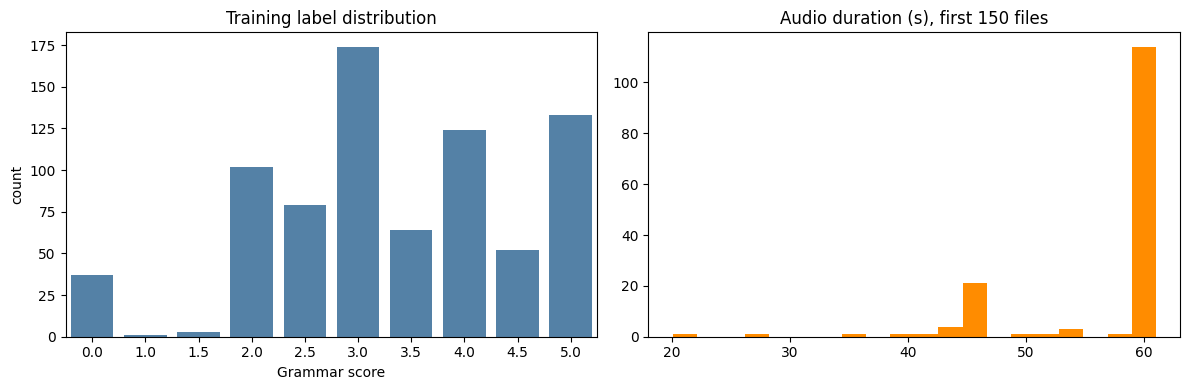

count    769.000000
mean       3.313394
std        1.239000
min        0.000000
25%        2.500000
50%        3.000000
75%        4.000000
max        5.000000
Name: label, dtype: float64
Sample rate: 16000


In [3]:
import soundfile as sf
durs = [sf.info(p).duration for p in train_df.path[:150]]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x=train_df.label, ax=ax[0], color="steelblue")
ax[0].set_title("Training label distribution"); ax[0].set_xlabel("Grammar score")
ax[1].hist(durs, bins=20, color="darkorange"); ax[1].set_title("Audio duration (s), first 150 files")
plt.tight_layout(); plt.show()
print(train_df.label.describe())
print("Sample rate:", sf.info(train_df.path[0]).samplerate)

**Observations.** Labels are concentrated around 2–5; a block of `0` scores (likely empty / unintelligible recordings) and almost no 1–1.5. Predicting the mean (~3.3) gives RMSE ≈ 1.24, the baseline to beat. Clips are 45–60 s, so a single 30 s Whisper window would discard half of each recording – we process two windows.

## 3. Feature extraction

### 3.1 Transcripts (Whisper ASR)
Transcripts + ASR confidence are cached. If the cache written by the previous notebook version (`features_base.pkl`) exists it is reused, which saves ~20 minutes.

In [4]:
import whisper

def transcribe(asr, audio):
    res = asr.transcribe(audio, language="en", fp16=(DEVICE == "cuda"),
                         temperature=0.0, condition_on_previous_text=False,
                         initial_prompt=(VERB_PROMPT if VERBATIM else None))
    segs = res["segments"]
    return dict(
        text=res["text"].strip(),
        avg_logprob=np.mean([s["avg_logprob"] for s in segs]) if segs else -5.0,
        min_logprob=np.min([s["avg_logprob"] for s in segs]) if segs else -5.0,
        no_speech=np.mean([s["no_speech_prob"] for s in segs]) if segs else 1.0,
        compression=np.mean([s["compression_ratio"] for s in segs]) if segs else 0.0,
        n_segments=len(segs),
        duration=len(audio) / 16000,
    )

def load_whisper(size, device):
    m = whisper.load_model(size, device="cpu")
    if device == "mps":
        m._buffers["alignment_heads"] = None   # sparse buffer breaks .to("mps"); only needed for word timestamps
        m = m.to(device)
    return m

def run_asr(df):
    return pd.DataFrame([transcribe(asr, whisper.load_audio(p)) for p in tqdm(df.path, desc=f"ASR ({ASR_SIZE})")])

if os.path.exists(ASR_CACHE):
    d = pickle.load(open(ASR_CACHE, "rb")); tr_asr, te_asr = d["tr_asr"], d["te_asr"]
    print("Loaded ASR cache:", ASR_CACHE)
elif (not QUICK_TEST) and (not VERBATIM) and os.path.exists(LEGACY_ASR):
    d = pickle.load(open(LEGACY_ASR, "rb")); tr_asr, te_asr = d["tr_asr"], d["te_asr"]
    assert len(tr_asr) == len(train_df) and len(te_asr) == len(test_df)
    pickle.dump(dict(tr_asr=tr_asr, te_asr=te_asr), open(ASR_CACHE, "wb"))
    print("Reused transcripts from the previous run:", LEGACY_ASR)
else:
    asr, asr_dev = None, ("cpu" if DEVICE == "mps" else DEVICE)
    if DEVICE == "mps":                                  # try the Mac GPU, fall back to CPU if it misbehaves
        try:
            asr = load_whisper(ASR_SIZE, "mps")
            probe = asr.transcribe(whisper.load_audio(train_df.path.iloc[0]), language="en", fp16=False)["text"]
            assert len(probe.strip()) > 20, "empty transcript on MPS"
            asr_dev = "mps"
        except Exception as e:
            print("Transcription on MPS failed -> CPU. Reason:", repr(e)[:150]); asr = None
    if asr is None:
        asr = whisper.load_model(ASR_SIZE, device=asr_dev)
    print("ASR running on:", asr_dev)
    tr_asr, te_asr = run_asr(train_df), run_asr(test_df)
    pickle.dump(dict(tr_asr=tr_asr, te_asr=te_asr), open(ASR_CACHE, "wb"))
    del asr
print(tr_asr.shape, te_asr.shape)
tr_asr.head(3)

Loaded ASR cache: ./working/asr_base.pkl
(769, 7) (216, 7)


,text,avg_logprob,min_logprob,no_speech,compression,n_segments,duration
0,"Well, this petite land is very, very beautiful...",-0.789881,-0.925650,0.329121,1.326950,8,60.508375
1,"To see no of a school playground, our playgrou...",-0.489816,-0.537573,0.463885,1.502682,9,60.074688
2,I favorite place to visit is the beach. I love...,-0.303367,-0.528533,0.278274,1.687228,12,60.074688


### 3.2 Acoustic embeddings from several speech encoders (the main signal)
Experiments showed that acoustic embeddings carry most of the grammar-score information, so we use **several different encoders** as separate "views": Whisper encoders (small / medium) and self-supervised speech models (WavLM, HuBERT). For each recording and **every layer** we store the **mean** and **standard deviation** over time of the hidden states (valid frames only). Mean captures average speaking style; std captures variability (hesitations, pacing). Each view is cached on disk.

In [5]:
@torch.no_grad()
def pooled(hs_list):
    """hs_list: list of (T, d) tensors, one per layer -> (mean, std), each (L, d) float32 numpy."""
    return (np.stack([h.mean(0).numpy() for h in hs_list]).astype(np.float32),
            np.stack([h.std(0).numpy()  for h in hs_list]).astype(np.float32))

# ---------- Whisper encoder view ----------
def whisper_extractor(size):
    m = whisper.load_model(size, device="cpu")            # load on CPU, then move ONLY the encoder to the GPU
    enc = m.encoder.to(DEVICE).eval()
    store = []
    for blk in enc.blocks:                                 # forward hooks collect every layer's output
        blk.register_forward_hook(lambda mod, inp, out: store.append(out if torch.is_tensor(out) else out[0]))
    L, D = len(enc.blocks), m.dims.n_audio_state

    @torch.no_grad()
    def f(audio):
        win, frames = 30 * 16000, [[] for _ in range(L)]
        for start in range(0, max(len(audio), 1), win)[:2]:      # up to 2 windows of 30 s
            chunk = audio[start:start + win]
            if len(chunk) < 2 * 16000: continue
            n_valid = min(int(np.ceil(len(chunk) / 16000 * 50)), 1500)   # encoder frames: 50 / second
            mel = whisper.log_mel_spectrogram(whisper.pad_or_trim(chunk)).to(DEVICE)
            if DEVICE == "cuda": mel = mel.half()
            store.clear(); enc(mel.unsqueeze(0))
            for l, h in enumerate(store[:L]): frames[l].append(h[0, :n_valid].float().cpu())
        if not frames[0]:
            z = np.zeros((L, D), np.float32); return z, z
        return pooled([torch.cat(fr, 0) for fr in frames])
    return f, enc

# ---------- self-supervised speech model view (WavLM / HuBERT / wav2vec2) ----------
def ssl_extractor(name):
    import time
    from transformers import AutoFeatureExtractor, AutoModel
    fe = hf_load(AutoFeatureExtractor.from_pretrained, name)
    m  = hf_load(AutoModel.from_pretrained, name).eval()
    L_, D_ = m.config.num_hidden_layers + 1, m.config.hidden_size

    # --- benchmark: run a dummy 60 s clip on the GPU and on the CPU, keep whichever is faster ---
    x0 = torch.randn(1, 16000 * SSL_MAX_SEC)
    timings = {}
    for d in dict.fromkeys([DEVICE, "cpu"]):
        try:
            m.to(d)
            for _ in range(2):                                   # 1st call = warm-up, 2nd call is timed
                t = time.time(); m(x0.to(d), output_hidden_states=True)
                if d == "mps": torch.mps.synchronize()
                if d == "cuda": torch.cuda.synchronize()
                dt = time.time() - t
            timings[d] = dt
        except Exception as e:
            print(f"  {name}: device {d} failed ({repr(e)[:80]})")
    dev = min(timings, key=timings.get)
    m.to(dev)
    print(f"  {name}: seconds per clip -> " + ", ".join(f"{k}: {v:.2f}" for k, v in timings.items()) + f"  => using {dev}")

    @torch.no_grad()
    def f(audio):
        audio = audio[: 16000 * SSL_MAX_SEC]
        if len(audio) < 2 * 16000:
            z = np.zeros((L_, D_), np.float32); return z, z
        x = fe(audio, sampling_rate=16000, return_tensors="pt").input_values
        hs = m(x.to(dev), output_hidden_states=True).hidden_states
        return pooled([h[0].float().cpu() for h in hs])
    return f, m

def get_view(key, make_extractor):
    cache = os.path.join(WORK_DIR, f"emb_{key.replace('/', '_')}{TAG}.pkl")
    if os.path.exists(cache):
        print("Loaded cache:", cache); return pickle.load(open(cache, "rb"))
    part = cache + ".part"                                   # progress checkpoint: an interrupted run resumes here
    state = pickle.load(open(part, "rb")) if os.path.exists(part) else {}
    f, model = make_extractor()
    out = {}
    for split, df in (("tr", train_df), ("te", test_df)):
        ms, ss = state.get(split, ([], []))
        for i in tqdm(range(len(ms), len(df)), initial=len(ms), total=len(df), desc=f"{key} [{split}]"):
            m_, s_ = f(whisper.load_audio(df.path.iloc[i])); ms.append(m_); ss.append(s_)
            if (i + 1) % 50 == 0:
                state[split] = (ms, ss); pickle.dump(state, open(part, "wb"))
        state[split] = (ms, ss)
        out[f"{split}_m"], out[f"{split}_s"] = np.stack(ms), np.stack(ss)
    pickle.dump(out, open(cache, "wb"))
    if os.path.exists(part): os.remove(part)
    del model, f; import gc; gc.collect()
    if DEVICE == "cuda": torch.cuda.empty_cache()
    return out

VIEWS = {}
for size in WHISPER_ENCODERS:
    VIEWS[f"whisper-{size}"] = get_view(size, lambda size=size: whisper_extractor(size))
for name in SSL_MODELS:
    try:
        VIEWS[name.split("/")[-1]] = get_view(name, lambda name=name: ssl_extractor(name))
    except Exception as e:
        print(f"!! Skipping {name}: {repr(e)[:150]}")
for k, v in VIEWS.items(): print(f"{k:22s} train mean {v['tr_m'].shape} | test {v['te_m'].shape}")

Loaded cache: ./working/emb_small.pkl
Loaded cache: ./working/emb_medium.pkl
whisper-small          train mean (769, 12, 768) | test (216, 12, 768)
whisper-medium         train mean (769, 24, 1024) | test (216, 24, 1024)


### 3.3 Cross-validation setup and layer-wise probe
Which layer of each encoder carries the most grammar information? We fit a Ridge regressor on each layer's mean-pooled embedding and compare 5-fold CV RMSE (nested alpha selection). The best three layers per view are kept. The same folds are reused for every model later.

whisper-small          selected layers [7, 8, 9] | best single layer 9 (RMSE 0.563)
whisper-medium         selected layers [14, 15, 18] | best single layer 18 (RMSE 0.551)


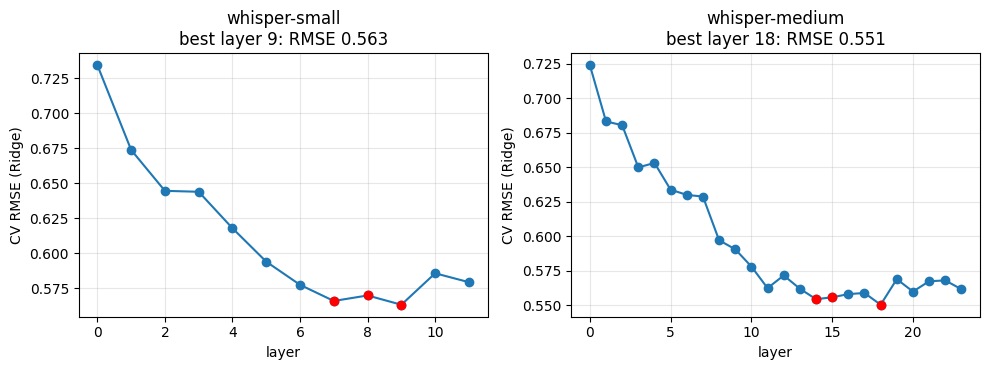

In [6]:
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge, RidgeCV, LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

def rmse(a, b): return float(np.sqrt(mean_squared_error(a, b)))
strat = np.clip(np.round(y), 1, 5).astype(int)           # merge the rare 0/1 scores into one stratum
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(np.zeros(len(y)), strat))

def cv_predict(make, X):
    p = np.zeros(len(y))
    for tr_i, va_i in folds:
        p[va_i] = make().fit(X[tr_i], y[tr_i]).predict(X[va_i])
    return np.clip(p, 0, 5)

SEL = {}                       # per view: selected layers
fig, axes = plt.subplots(1, len(VIEWS), figsize=(5 * len(VIEWS), 3.8), squeeze=False)
for ax, (vname, v) in zip(axes[0], VIEWS.items()):
    Lv = v["tr_m"].shape[1]
    lr = np.array([rmse(y, cv_predict(lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(0, 4.5, 10))), v["tr_m"][:, l])) for l in range(Lv)])
    top = sorted(np.argsort(lr)[:3].tolist()); best = int(np.argmin(lr))
    SEL[vname] = dict(top=top, best=best, rmse=lr)
    ax.plot(range(Lv), lr, "o-"); ax.scatter(top, lr[top], color="red", zorder=3)
    ax.set_title(f"{vname}\nbest layer {best}: RMSE {lr[best]:.3f}"); ax.set_xlabel("layer"); ax.set_ylabel("CV RMSE (Ridge)"); ax.grid(alpha=.3)
    print(f"{vname:22s} selected layers {top} | best single layer {best} (RMSE {lr[best]:.3f})")
plt.tight_layout(); plt.show()

### 3.4 Text features: surface statistics + GPT-2 perplexity
* **Perplexity** of the transcript under GPT-2 is a proxy for grammatical naturalness (overall and per sentence: mean / median / max).
* Surface features: word count, speaking rate, type-token ratio, sentence-length statistics, filler-word rate, immediate word repetitions (repairs / false starts), long-word share, and subordinating-conjunction rate (proxy for complex grammar).

In [7]:
from transformers import GPT2LMHeadModel, GPT2TokenizerFast
tok = hf_load(GPT2TokenizerFast.from_pretrained, "gpt2")
lm  = hf_load(GPT2LMHeadModel.from_pretrained, "gpt2").to(DEVICE).eval()

@torch.no_grad()
def ppl(text, max_len=256):
    if len(text.split()) < 3: return np.nan
    ids = tok(text, return_tensors="pt", truncation=True, max_length=max_len).input_ids.to(DEVICE)
    ids = torch.cat([torch.tensor([[tok.bos_token_id]], device=DEVICE), ids], 1)
    loss = lm(ids, labels=ids).loss.item()
    return float(np.exp(min(loss, 15)))

FILLERS = {"um", "uh", "er", "erm", "hmm", "ah", "like", "actually", "basically"}
SUBORD  = {"because", "although", "though", "while", "whereas", "since", "unless", "if", "when", "which", "that", "who", "whose", "whom", "however", "therefore"}

def text_features(text, duration):
    words = re.findall(r"[A-Za-z']+", text.lower())
    sents = [s.strip() for s in re.split(r"[.!?]+", text) if len(s.strip().split()) > 0]
    n = max(len(words), 1)
    sent_lens = [len(s.split()) for s in sents] or [0]
    sent_ppl = [ppl(s) for s in sents if len(s.split()) >= 4]
    sent_ppl = [x for x in sent_ppl if not np.isnan(x)] or [np.nan]
    return dict(
        n_words=len(words), wpm=len(words) / max(duration, 1) * 60,
        ttr=len(set(words)) / n, n_sents=len(sents),
        mean_sent_len=np.mean(sent_lens), max_sent_len=np.max(sent_lens), std_sent_len=np.std(sent_lens),
        short_sent_frac=np.mean([l <= 3 for l in sent_lens]),
        filler_rate=sum(w in FILLERS for w in words) / n,
        repeat_rate=sum(a == b for a, b in zip(words, words[1:])) / n,
        long_word_frac=np.mean([len(w) >= 7 for w in words]) if words else 0,
        subord_rate=sum(w in SUBORD for w in words) / n,
        ppl_all=ppl(text, 400), ppl_mean=np.nanmean(sent_ppl), ppl_med=np.nanmedian(sent_ppl), ppl_max=np.nanmax(sent_ppl),
    )

def build_hand_features(asr_df):
    tf = pd.DataFrame([text_features(t, d) for t, d in tqdm(zip(asr_df.text, asr_df.duration), total=len(asr_df), desc="text feats")])
    out = pd.concat([asr_df.drop(columns=["text"]).reset_index(drop=True), tf], axis=1)
    for c in ["ppl_all", "ppl_mean", "ppl_med", "ppl_max"]:
        out[c] = np.log1p(out[c])            # perplexity is heavy-tailed -> log
    out["compression"] = out["compression"].clip(upper=5)          # a few hallucination loops give extreme values
    out["max_sent_len"] = out["max_sent_len"].clip(upper=100)
    out["mean_sent_len"] = out["mean_sent_len"].clip(upper=60)
    return out

X_hand_tr = build_hand_features(tr_asr)
X_hand_te = build_hand_features(te_asr)
med = X_hand_tr.median()
X_hand_tr, X_hand_te = X_hand_tr.fillna(med), X_hand_te.fillna(med)   # empty transcripts -> median
X_hand_tr.describe().T.head(25)

text feats: 100%|██████████| 216/216 [00:27<00:00,  7.88it/s]


,count,mean,std,min,25%,50%,75%,max
avg_logprob,769.0,-0.422175,0.238359,-5.000000,-0.494822,-0.375976,-0.293037,-0.172541
min_logprob,769.0,-0.602846,0.330337,-5.000000,-0.737571,-0.519517,-0.384064,-0.191848
no_speech,769.0,0.270307,0.144035,0.022978,0.160502,0.254551,0.352775,1.000000
compression,769.0,1.522471,0.424110,0.000000,1.385597,1.481041,1.556094,5.000000
n_segments,769.0,8.444733,3.301259,0.000000,6.000000,8.000000,10.000000,42.000000
duration,769.0,55.781067,7.908964,20.060000,54.186687,60.074688,60.074688,61.040000
n_words,769.0,100.711313,28.624179,0.000000,82.000000,101.000000,120.000000,262.000000
wpm,769.0,109.051121,28.486322,0.000000,90.969677,110.519308,127.840865,261.674270
ttr,769.0,0.605671,0.106591,0.000000,0.548673,0.610000,0.668966,0.893333
n_sents,769.0,6.107932,3.182807,0.000000,4.000000,6.000000,8.000000,30.000000


### 3.5 Grammar-correctness features (CoLA)
A RoBERTa classifier fine-tuned on **CoLA** (Corpus of Linguistic Acceptability) scores every transcript sentence for grammatical acceptability. Per recording we keep the mean probability, the worst sentence, and the fraction of sentences judged acceptable. A sanity check on two example sentences decides which output index means "acceptable". Runs on the GPU.

In [8]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

cola_name = "textattack/roberta-base-CoLA"
cola_tok = hf_load(AutoTokenizer.from_pretrained, cola_name)
cola = hf_load(AutoModelForSequenceClassification.from_pretrained, cola_name).to(DEVICE).eval()

@torch.no_grad()
def cola_probs(sents, idx):
    enc_ = cola_tok(sents, return_tensors="pt", padding=True, truncation=True, max_length=64).to(DEVICE)
    return cola(**enc_).logits.softmax(-1)[:, idx].cpu().numpy()

good, bad = "She went to the market and bought some fresh vegetables.", "She go market buy vegetable yesterday not."
ACCEPT_IDX = 1 if cola_probs([good], 1)[0] > cola_probs([bad], 1)[0] else 0
print("acceptable-sentence index:", ACCEPT_IDX, "| good:", cola_probs([good], ACCEPT_IDX)[0].round(3), "| bad:", cola_probs([bad], ACCEPT_IDX)[0].round(3))

def cola_feats(text):
    sents = [s.strip() for s in re.split(r"(?<=[.!?])\s+", text) if len(s.split()) >= 3]
    if not sents:
        return dict(cola_mean=np.nan, cola_min=np.nan, cola_frac=np.nan)
    p = np.concatenate([cola_probs(sents[i:i + 32], ACCEPT_IDX) for i in range(0, len(sents), 32)])
    return dict(cola_mean=p.mean(), cola_min=p.min(), cola_frac=(p > 0.5).mean())

cf_tr = pd.DataFrame([cola_feats(t) for t in tqdm(tr_asr.text, desc="CoLA train")])
cf_te = pd.DataFrame([cola_feats(t) for t in tqdm(te_asr.text, desc="CoLA test")])

X_hand_tr = pd.concat([X_hand_tr.reset_index(drop=True), cf_tr], axis=1)
X_hand_te = pd.concat([X_hand_te.reset_index(drop=True), cf_te], axis=1)
med = X_hand_tr.median()
X_hand_tr, X_hand_te = X_hand_tr.fillna(med), X_hand_te.fillna(med)
print("hand-crafted feature matrix:", X_hand_tr.shape)

Some weights of the model checkpoint at textattack/roberta-base-CoLA were not used when initializing RobertaForSequenceClassification: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


acceptable-sentence index: 1 | good: 0.976 | bad: 0.063


CoLA test: 100%|██████████| 216/216 [00:08<00:00, 26.02it/s]

hand-crafted feature matrix: (769, 25)


In [9]:
try:
    from sentence_transformers import SentenceTransformer
    st_model = hf_load(SentenceTransformer, "sentence-transformers/all-MiniLM-L6-v2", device=DEVICE)
    X_txt_tr = st_model.encode(tr_asr.text.tolist(), batch_size=32, show_progress_bar=True)
    X_txt_te = st_model.encode(te_asr.text.tolist(), batch_size=32, show_progress_bar=True)
    print("Using MiniLM embeddings")
except Exception as e:                                   # e.g. no internet -> local TF-IDF + SVD fallback
    print("MiniLM unavailable, using TF-IDF + SVD instead:", repr(e)[:120])
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.decomposition import TruncatedSVD
    tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True)
    A = tfidf.fit_transform(tr_asr.text)
    svd = TruncatedSVD(min(128, A.shape[1] - 1), random_state=SEED).fit(A)
    X_txt_tr, X_txt_te = svd.transform(A), svd.transform(tfidf.transform(te_asr.text))

# acoustic feature blocks: per view = mean of its top layers + std of its best layer
AUD_TR, AUD_TE = {}, {}
for vname, v in VIEWS.items():
    t, b_ = SEL[vname]["top"], SEL[vname]["best"]
    AUD_TR[vname] = np.hstack([v["tr_m"][:, t].reshape(len(v["tr_m"]), -1), v["tr_s"][:, b_]])
    AUD_TE[vname] = np.hstack([v["te_m"][:, t].reshape(len(v["te_m"]), -1), v["te_s"][:, b_]])
print({k: x.shape for k, x in AUD_TR.items()}, "| text:", X_txt_tr.shape, "| hand:", X_hand_tr.shape)

Batches: 100%|██████████| 7/7 [00:00<00:00,  7.93it/s]

Using MiniLM embeddings
{'whisper-small': (769, 3072), 'whisper-medium': (769, 4096)} | text: (769, 384) | hand: (769, 25)


### 3.6 Which hand-crafted features relate to the grammar score?

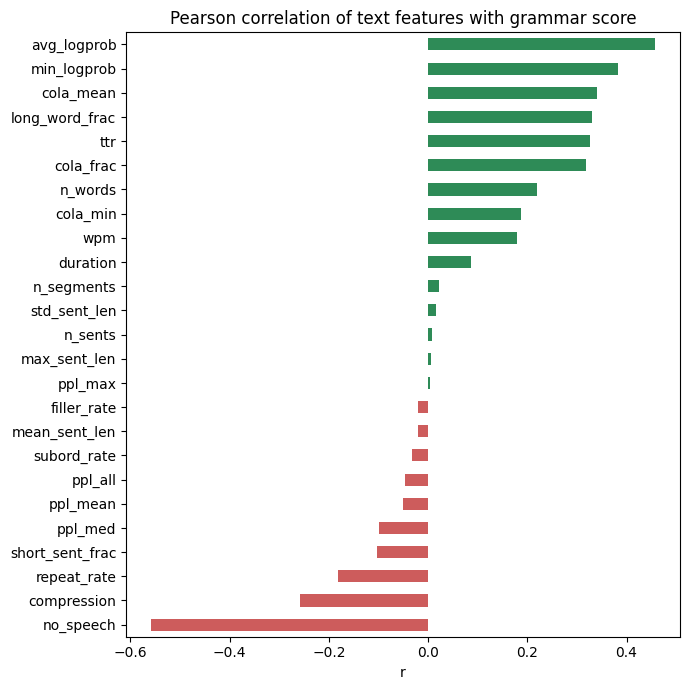

In [10]:
corr = X_hand_tr.assign(label=y).corr()["label"].drop("label").sort_values()
plt.figure(figsize=(7, 7)); corr.plot.barh(color=np.where(corr > 0, "seagreen", "indianred"))
plt.title("Pearson correlation of text features with grammar score"); plt.xlabel("r"); plt.tight_layout(); plt.show()

Perplexity-type features should correlate **negatively** (more natural text → higher score) while ASR confidence, CoLA acceptability, sentence length and vocabulary richness correlate **positively**.

## 4. Modelling

Each feature view gets its own regressors, evaluated with the same stratified 5-fold CV. SVR hyper-parameters are tuned by an **inner** 3-fold grid search inside every outer fold (nested CV), so the reported CV scores stay honest. Out-of-fold (OOF) predictions are blended afterwards.

In [11]:
NPC = lambda k: max(2, min(k, len(y) * 8 // 15 - 2))     # PCA size that also fits inside the inner CV folds (matters for the tiny QUICK_TEST subset)
ALPHAS = np.logspace(0, 4.5, 10)

def svr_grid(n_pc=128):
    pipe = make_pipeline(StandardScaler(), PCA(NPC(n_pc), random_state=SEED), SVR())
    grid = {"svr__C": [1, 3, 10, 30], "svr__epsilon": [0.1, 0.3]}
    return GridSearchCV(pipe, grid, cv=3, scoring="neg_root_mean_squared_error", n_jobs=1)

models, TR, TE = {}, {}, {}
for vname in VIEWS:
    TR[f"aud:{vname}"], TE[f"aud:{vname}"] = AUD_TR[vname], AUD_TE[vname]
    models[f"RidgeCV | {vname}"]  = (lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=ALPHAS)), f"aud:{vname}")
    models[f"SVR-grid| {vname}"]  = (lambda: svr_grid(128), f"aud:{vname}")
TR["audall"], TE["audall"] = np.hstack(list(AUD_TR.values())), np.hstack(list(AUD_TE.values()))
TR["txt"],  TE["txt"]  = X_txt_tr, X_txt_te
TR["hand"], TE["hand"] = X_hand_tr.values, X_hand_te.values
TR["all"],  TE["all"]  = np.hstack([TR["audall"], TR["txt"], TR["hand"]]), np.hstack([TE["audall"], TE["txt"], TE["hand"]])
models.update({
    "RidgeCV | all acoustic views":  (lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=ALPHAS)), "audall"),
    "SVR-grid| all acoustic views":  (lambda: svr_grid(192), "audall"),
    "RidgeCV | MiniLM text":         (lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=ALPHAS)), "txt"),
    "HistGB  | text+CoLA features":  (lambda: HistGradientBoostingRegressor(max_depth=3, learning_rate=0.04, max_iter=300, l2_regularization=1.0, random_state=SEED), "hand"),
    "RidgeCV | text+CoLA features":  (lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=ALPHAS)), "hand"),
    "SVR-grid| everything":          (lambda: svr_grid(224), "all"),
})

oof = {}
for name, (mk, blk) in models.items():
    oof[name] = cv_predict(mk, TR[blk])
    print(f"{name:34s}  CV RMSE={rmse(y, oof[name]):.3f}  Pearson={pearsonr(y, oof[name])[0]:.3f}")
print(f"{'Baseline (mean)':34s}  CV RMSE={rmse(y, np.full_like(y, y.mean())):.3f}")

RidgeCV | whisper-small             CV RMSE=0.557  Pearson=0.894
SVR-grid| whisper-small             CV RMSE=0.537  Pearson=0.902
RidgeCV | whisper-medium            CV RMSE=0.536  Pearson=0.902
SVR-grid| whisper-medium            CV RMSE=0.522  Pearson=0.908
RidgeCV | all acoustic views        CV RMSE=0.542  Pearson=0.900
SVR-grid| all acoustic views        CV RMSE=0.516  Pearson=0.910
RidgeCV | MiniLM text               CV RMSE=0.946  Pearson=0.645
HistGB  | text+CoLA features        CV RMSE=0.791  Pearson=0.770
RidgeCV | text+CoLA features        CV RMSE=0.845  Pearson=0.745
SVR-grid| everything                CV RMSE=0.516  Pearson=0.910
Baseline (mean)                     CV RMSE=1.238


### 4.1 Stacking
A non-negative linear regression learns how much to trust each base model (non-negativity keeps the blend stable with ~770 samples). Its quality is estimated with CV over the OOF matrix.

In [12]:
names = list(models)
O = np.column_stack([oof[n] for n in names])
stack = LinearRegression(positive=True).fit(O, y)
print(dict(zip(names, np.round(stack.coef_, 3))), "intercept", round(stack.intercept_, 3))

p_stack = np.zeros(len(y))
for tr_i, va_i in folds:
    s = LinearRegression(positive=True).fit(O[tr_i], y[tr_i]); p_stack[va_i] = s.predict(O[va_i])
p_stack = np.clip(p_stack, 0, 5)
cv_rmse, cv_r = rmse(y, p_stack), pearsonr(y, p_stack)[0]
print(f"\nStacked ensemble  CV RMSE = {cv_rmse:.3f} | CV Pearson = {cv_r:.3f}")

{'RidgeCV | whisper-small': np.float64(0.0), 'SVR-grid| whisper-small': np.float64(0.033), 'RidgeCV | whisper-medium': np.float64(0.372), 'SVR-grid| whisper-medium': np.float64(0.101), 'RidgeCV | all acoustic views': np.float64(0.0), 'SVR-grid| all acoustic views': np.float64(0.449), 'RidgeCV | MiniLM text': np.float64(0.132), 'HistGB  | text+CoLA features': np.float64(0.01), 'RidgeCV | text+CoLA features': np.float64(0.052), 'SVR-grid| everything': np.float64(0.0)} intercept -0.522

Stacked ensemble  CV RMSE = 0.496 | CV Pearson = 0.916


## 5. Evaluation & visualisations (cross-validated)

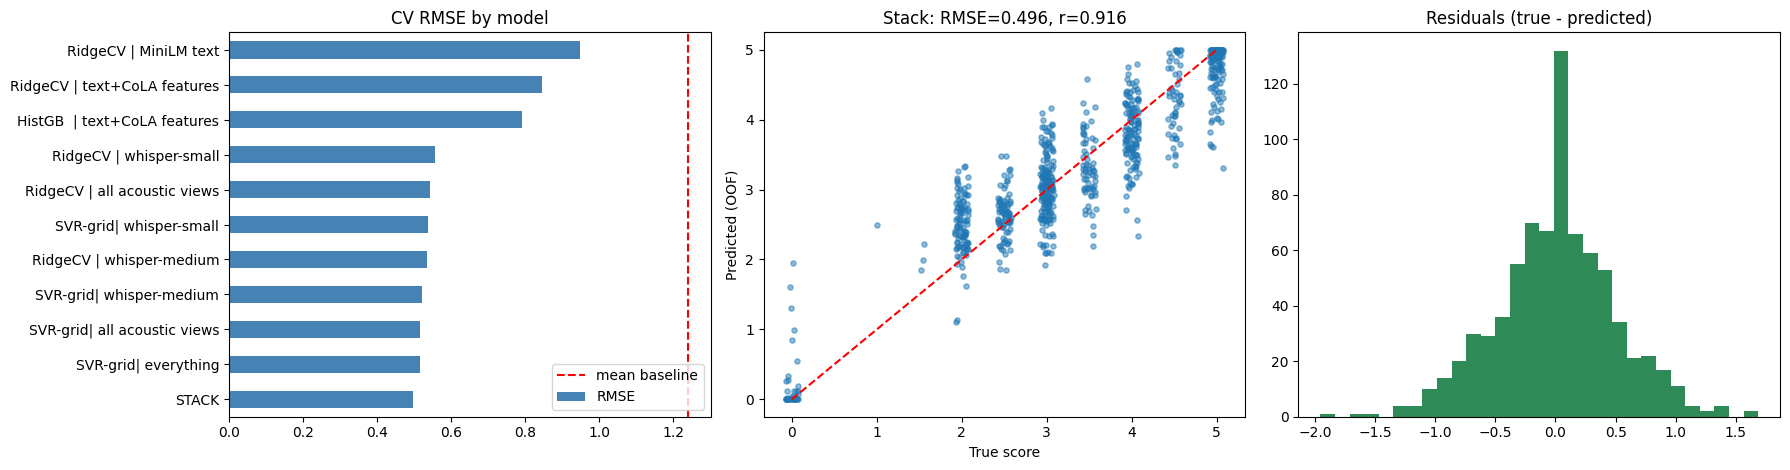

Mean absolute error per true label:
label     0.0    1.0   1.5      2.0     2.5      3.0     3.5      4.0    4.5  \
mean    0.242  1.488  0.52    0.554   0.285    0.348   0.425    0.396   0.44   
count  37.000  1.000  3.00  102.000  79.000  174.000  64.000  124.000  52.00   

label      5.0  
mean     0.263  
count  133.000  


In [13]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
res = pd.DataFrame({"RMSE": [rmse(y, oof[n]) for n in names] + [cv_rmse]}, index=names + ["STACK"]).sort_values("RMSE")
res.RMSE.plot.barh(ax=ax[0], color="steelblue"); ax[0].axvline(rmse(y, np.full_like(y, y.mean())), color="red", ls="--", label="mean baseline")
ax[0].set_title("CV RMSE by model"); ax[0].legend()
jit = np.random.uniform(-.08, .08, len(y))
ax[1].scatter(y + jit, p_stack, alpha=.5, s=14); ax[1].plot([0, 5], [0, 5], "r--")
ax[1].set_xlabel("True score"); ax[1].set_ylabel("Predicted (OOF)"); ax[1].set_title(f"Stack: RMSE={cv_rmse:.3f}, r={cv_r:.3f}")
ax[2].hist(y - p_stack, bins=30, color="seagreen"); ax[2].set_title("Residuals (true - predicted)")
plt.tight_layout(); plt.show()

print("Mean absolute error per true label:")
print(pd.DataFrame({"label": y, "abs_err": np.abs(y - p_stack)}).groupby("label").abs_err.agg(["mean", "count"]).round(3).T)

## 6. Final fit, training-set RMSE (required) and test predictions
All base models are refit on the **full training set**, blended with the stacker, and used to predict the test set.

  TRAINING RMSE (full-fit model, train data) : 0.1782
  TRAINING Pearson                           : 0.9899
  5-fold CV RMSE (honest generalisation)     : 0.4957
  5-fold CV Pearson                          : 0.9165


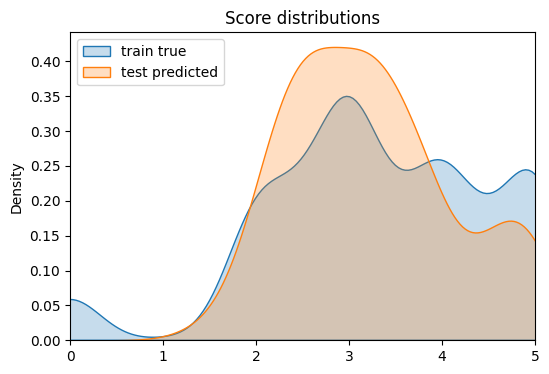

In [14]:
final_models = {n: models[n][0]().fit(TR[models[n][1]], y) for n in names}
train_pred_base = np.column_stack([np.clip(final_models[n].predict(TR[models[n][1]]), 0, 5) for n in names])
train_pred = np.clip(stack.predict(train_pred_base), 0, 5)

TRAIN_RMSE = rmse(y, train_pred)
print("=" * 55)
print(f"  TRAINING RMSE (full-fit model, train data) : {TRAIN_RMSE:.4f}")
print(f"  TRAINING Pearson                           : {pearsonr(y, train_pred)[0]:.4f}")
print(f"  5-fold CV RMSE (honest generalisation)     : {cv_rmse:.4f}")
print(f"  5-fold CV Pearson                          : {cv_r:.4f}")
print("=" * 55)

test_base = np.column_stack([np.clip(final_models[n].predict(TE[models[n][1]]), 0, 5) for n in names])
test_pred = np.clip(stack.predict(test_base), 0, 5)

plt.figure(figsize=(6, 4)); sns.kdeplot(y, label="train true", fill=True); sns.kdeplot(test_pred, label="test predicted", fill=True)
plt.legend(); plt.title("Score distributions"); plt.xlim(0, 5); plt.show()

In [15]:
# submission: same columns as sample_submission.csv, one row per file in test.csv
submission = pd.DataFrame({"filename": test_df.filename, "label": test_pred})
assert list(submission.columns) == list(sample_sub.columns)
submission.to_csv(os.path.join(WORK_DIR, "submission.csv"), index=False)
print(submission.shape); submission.head()

(216, 2)


,filename,label
0,audio_128.wav,3.012000
1,audio_156.wav,4.074513
2,audio_19.wav,4.735976
3,audio_108.wav,2.341053
4,audio_206.wav,2.328256


## 7. Discussion

**Pipeline architecture.** `wav (16 kHz)` → (a) several speech encoders (Whisper small/medium, WavLM, HuBERT; all layers, mean + std pooled) → layer probe per encoder → acoustic features; (b) Whisper ASR → transcript → surface stats, GPT-2 perplexity, CoLA acceptability, MiniLM embedding. Each view → its own regressors (Ridge / SVR with nested grid search / gradient boosting) → non-negative stacker → clip to [0, 5].

**Results.** See §5–6: the *training* RMSE is (as always) lower than the cross-validated RMSE, which is the number that predicts leaderboard behaviour. Compare the CV RMSE with the mean-prediction baseline (≈ 1.24).

**Interpretation.** The layer probe shows where in the encoder grammar-relevant information sits; the acoustic view dominates because proficiency shows up in fluency and delivery; perplexity, CoLA and ASR confidence add complementary text-level evidence; stacking lowers variance.

**Limitations & ideas**
* ASR often "auto-corrects" ungrammatical speech, hiding errors – a larger Whisper model for transcripts helps the text view.
* Labels are sparse at the low end (0–1.5); such scores are over-predicted (regression to the mean) – see the per-label error table.
* Fine-tune an encoder end-to-end with more compute, add larger SSL models (wav2vec2-large, WavLM-large), or try `VERBATIM = True` so that ASR keeps the speaker's grammar errors.